# 09 — Partie G : comparaison et décision

Tableau final : qualité, robustesse, coût. Puis la matrice de confusion du modèle retenu.

**Sources et machines :**
- Qualité et robustesse : Partie F (`results/F_bilan.csv`, `results/F5_intervalles.csv`).
- Temps d'entraînement : journaux des Parties A à E, mesurés sur le portable (RTX 4070 Laptop).
- Latence et taille : `scripts/run_G.py`, mesurées sur CPU (Intel i7-12700, 12 threads), un argument à la fois, moyenne sur 100 arguments du test (20 pour le NLI).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import multilabel_confusion_matrix
from valeval.data import VALUES, label_matrix, load_split

R, RUNS, F = Path("../results"), Path("../cache/runs"), Path("../cache/final")
bilan = pd.read_csv(R / "F_bilan.csv").set_index("modèle")
ic = pd.read_csv(R / "F5_intervalles.csv").set_index("modèle")
cout = pd.read_csv(R / "G_cout.csv").set_index("modèle")

def temps(fichier, graines=(42, 43, 44)):
    return np.mean([json.loads((RUNS / f"{fichier}_seed{g}.json").read_text(encoding="utf-8"))["temps_s"] for g in graines])

journal = pd.read_csv(R / "results.csv")
t_base = journal[(journal.modele == "baseline_tfidf_lr") & journal.notes.fillna("").str.startswith("C=1, seuil unique")].temps_entrainement_s.iloc[0]
d1 = [l for l in json.loads((RUNS / "D1.json").read_text(encoding="utf-8")) if l["pooling"] == "moyenne" and l["C"] == 0.0003][0]
entrainement = {"Baseline TF-IDF": t_base, "B1 NLI": 0.0, "C1 BiLSTM + GloVe": temps("C1_glove_max"),
                "D1 RoBERTa gelé + LR": 15 + d1["temps_s"], "D2 RoBERTa gelé + tête": 15 + temps("D2"),
                "E1 RoBERTa fine-tuné": temps("E1_roberta_ep8"), "E2 multi-tâche (λ=0,3)": temps("E2_roberta_lam0.3_ep8")}
f4 = {"Baseline TF-IDF": "baseline_tfidf_lr_seed0", "C1 BiLSTM + GloVe": "C1_bilstm_glove_seed42", "E1 RoBERTa fine-tuné": "E1_roberta_ep8_seed42"}
chute = {}
for m, f in f4.items():
    t = pd.DataFrame(json.loads((F / f"{f}.json").read_text(encoding="utf-8"))["f4"]["train_k200"])
    chute[m] = 1 - t.restent.sum() / t.detectes.sum()

tab = pd.DataFrame({"macro-F1 val": bilan.validation, "macro-F1 test": bilan.test,
                    "IC 95 % test (1re graine)": ic["IC 2,5 %"].round(3).astype(str) + " – " + ic["IC 97,5 %"].round(3).astype(str),
                    "Nahj al-Balagha": bilan["test-nahjalbalagha"], "NYT": bilan["test-nyt"],
                    "chute F4 (mots-clés)": pd.Series(chute),
                    "entraînement (s, GPU)": pd.Series(entrainement).round(0),
                    "latence CPU (ms / argument)": cout["latence CPU (ms)"], "taille (Mo)": cout["taille (Mo)"]}).drop(index="« toutes les valeurs » (plancher)", errors="ignore")
tab = tab.sort_values("macro-F1 test", ascending=False)
tab.to_csv(R / "G_tableau_final.csv")
tab.round(3)

,macro-F1 val,macro-F1 test,IC 95 % test (1re graine),Nahj al-Balagha,NYT,chute F4 (mots-clés),"entraînement (s, GPU)",latence CPU (ms / argument),taille (Mo)
E1 RoBERTa fine-tuné,0.483,0.473,0.459 – 0.486,0.232,0.229,0.134,193.0,36.713,498.724
"E2 multi-tâche (λ=0,3)",0.482,0.469,0.454 – 0.483,0.229,0.218,NaN,194.0,37.630,498.737
D1 RoBERTa gelé + LR,0.446,0.436,0.423 – 0.448,0.200,0.229,NaN,16.0,33.716,498.723
D2 RoBERTa gelé + tête,0.450,0.426,0.409 – 0.439,0.192,0.196,NaN,93.0,35.863,502.496
B1 NLI,0.427,0.405,0.389 – 0.418,0.214,0.170,NaN,0.0,2809.206,1740.417
C1 BiLSTM + GloVe,0.415,0.394,0.393 – 0.419,0.166,0.176,0.154,87.0,3.149,481.813
Baseline TF-IDF,0.394,0.368,0.355 – 0.381,0.178,0.145,0.215,2.0,3.512,8.743


Les scores Nahj al-Balagha et NYT sont les macro-F1 sur les 20 valeurs. Sur NYT, 3 valeurs n'ont aucun positif ; la Partie F donne aussi le score limité aux valeurs présentes.

La colonne « macro-F1 test » est la moyenne des graines ; l'intervalle de confiance porte sur la première graine (bootstrap de 1 000 tirages, Partie F5). Le macro-F1 val du NLI (0,427) est optimiste : ses 20 seuils ont été réglés sur ce même val ; son score honnête en validation croisée était 0,407 (Partie B1).

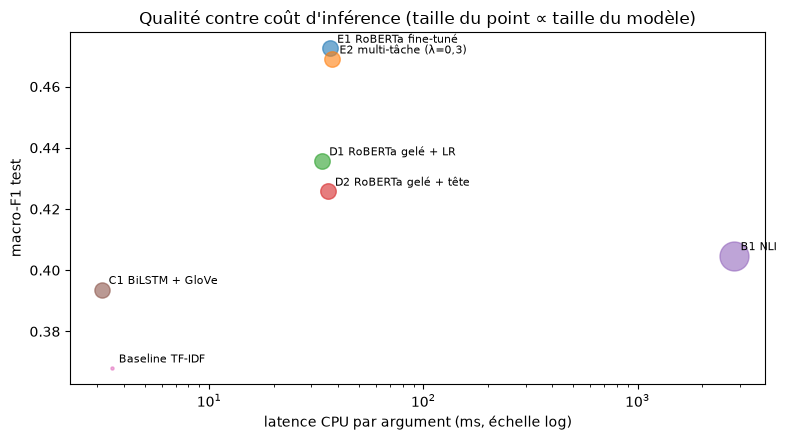

In [2]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for m, l in tab.iterrows():
    ax.scatter(l["latence CPU (ms / argument)"], l["macro-F1 test"], s=max(l["taille (Mo)"], 20) / 4, alpha=.6)
    ax.annotate(m, (l["latence CPU (ms / argument)"], l["macro-F1 test"]), fontsize=8, xytext=(5, 4), textcoords="offset points")
ax.set_xscale("log")
ax.set(xlabel="latence CPU par argument (ms, échelle log)", ylabel="macro-F1 test",
       title="Qualité contre coût d'inférence (taille du point ∝ taille du modèle)")
plt.tight_layout(); plt.savefig("../figures/G_qualite_cout.png", dpi=120); plt.show()

## Matrice de confusion du modèle retenu
E1 (RoBERTa fine-tuné, graine 42), seuil 0,52 choisi sur val. En multi-label, il y a une matrice 2×2 par valeur : vrais positifs, faux positifs, faux négatifs, vrais négatifs.

seuil : 0.5200000000000001 | total VP 3213 FP 3953 FN 1558 VN 22796


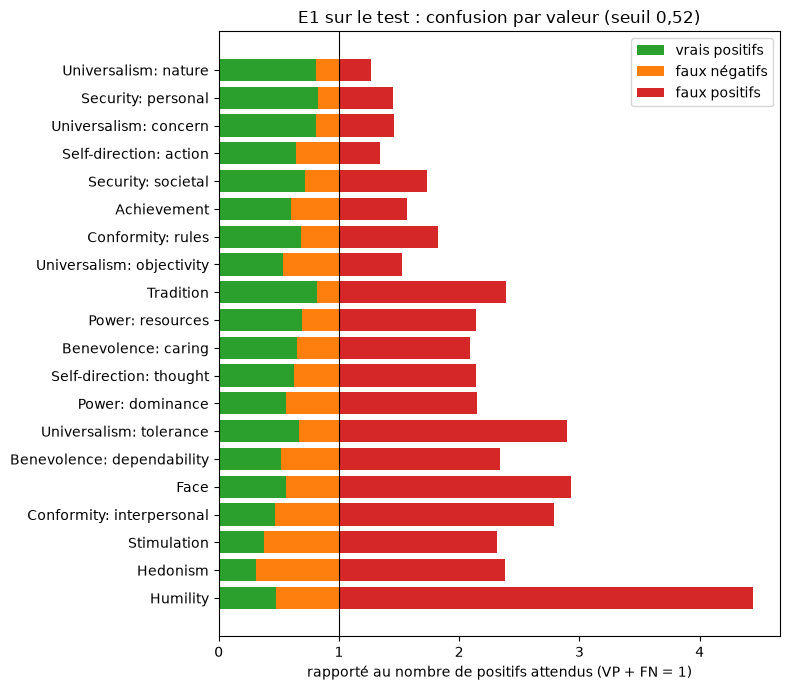

,VP,FP,FN,VN,précision,rappel,F1
Universalism: nature,116,38,28,1394,0.753,0.806,0.779
Security: personal,443,240,94,799,0.649,0.825,0.726
Universalism: concern,477,268,111,720,0.640,0.811,0.716
Self-direction: action,252,134,139,1051,0.653,0.645,0.649
Security: societal,285,290,112,889,0.496,0.718,0.586
Achievement,249,233,163,931,0.517,0.604,0.557
Conformity: rules,196,237,91,1052,0.453,0.683,0.544
Universalism: objectivity,250,247,221,858,0.503,0.531,0.517
Tradition,137,233,31,1175,0.370,0.815,0.509
Power: resources,73,120,32,1351,0.378,0.695,0.490


In [3]:
test = load_split("test")
y = label_matrix(test)
seuil = float(json.loads((F / "E1_roberta_ep8_seed42.json").read_text(encoding="utf-8"))["seuil"])
pred = np.load(F / "E1_roberta_ep8_seed42_test.npy") >= seuil
mc = multilabel_confusion_matrix(y, pred)
conf = pd.DataFrame({"VP": mc[:, 1, 1], "FP": mc[:, 0, 1], "FN": mc[:, 1, 0], "VN": mc[:, 0, 0]}, index=VALUES)
conf["précision"] = conf.VP / (conf.VP + conf.FP)
conf["rappel"] = conf.VP / (conf.VP + conf.FN)
conf["F1"] = 2 * conf.VP / (2 * conf.VP + conf.FP + conf.FN)
conf = conf.sort_values("F1", ascending=False)
print("seuil :", seuil, "| total VP", conf.VP.sum(), "FP", conf.FP.sum(), "FN", conf.FN.sum(), "VN", conf.VN.sum())

fig, ax = plt.subplots(figsize=(8, 7))
parts = conf[["VP", "FN", "FP"]].div(conf.VP + conf.FN, axis=0)
gauche = np.zeros(len(parts))
for col, couleur, nom in [("VP", "tab:green", "vrais positifs"), ("FN", "tab:orange", "faux négatifs"), ("FP", "tab:red", "faux positifs")]:
    ax.barh(parts.index, parts[col], left=gauche, color=couleur, label=nom)
    gauche += parts[col].values
ax.invert_yaxis(); ax.axvline(1, color="black", lw=.8)
ax.set(xlabel="rapporté au nombre de positifs attendus (VP + FN = 1)",
       title="E1 sur le test : confusion par valeur (seuil 0,52)")
ax.legend(loc="upper right"); plt.tight_layout(); plt.savefig("../figures/G_confusion.png", dpi=120); plt.show()
conf.round(3)

In [4]:
# Quelles valeurs le modèle prédit-il à tort à la place d'une autre ? (arguments où la valeur ligne est un FN)
paires = pd.DataFrame(0, index=VALUES, columns=VALUES)
for i in range(len(y)):
    for a in np.nonzero(y[i] & ~pred[i])[0]:
        for b in np.nonzero(~y[i].astype(bool) & pred[i])[0]:
            paires.iloc[a, b] += 1
top = paires.stack().sort_values(ascending=False).head(10)
top.rename_axis(["valeur manquée", "valeur prédite à tort"]).rename("arguments").to_frame()

arguments
valeur manquée            valeur prédite à tort             
Achievement               Universalism: concern           47
Universalism: objectivity Universalism: concern           46
                          Tradition                       44
                          Humility                        44
                          Security: societal              42
Achievement               Benevolence: caring             39
Self-direction: action    Benevolence: caring             39
Universalism: objectivity Universalism: tolerance         38
                          Benevolence: caring             38
                          Security: personal              38

**Lecture :**
- **Les faux positifs dominent** : 3 953 FP contre 1 558 FN. Le modèle trouve la plupart des valeurs présentes (rappel ≥ 0,6 pour 12 valeurs sur 20) mais en ajoute beaucoup, ce qui rejoint le surplus de « oui » vu en F1.
- **Le phénomène est le plus fort sur les valeurs rares :** *Humility* compte 255 FP pour 35 VP, *Face* 185 pour 54, *Universalism: tolerance* 370 pour 131. Avec un seuil unique, ces valeurs à faible fréquence sont prédites trop souvent.
- **Valeurs les mieux reconnues :** *Universalism: nature* (F1 0,78), *Security: personal* (0,73), *Universalism: concern* (0,72).
- **Confusions fréquentes :** quand *Achievement* ou *Universalism: objectivity* sont manqués, le modèle prédit souvent *Universalism: concern* ou *Benevolence: caring* à la place : des valeurs voisines, comme en F6.

## Décision (Q12)

| Critère | E1 RoBERTa fine-tuné | D1 RoBERTa gelé + LR | Baseline TF-IDF |
|---|---|---|---|
| Qualité (macro-F1 test) | **0,473** [0,459 – 0,486] | 0,436 [0,423 – 0,448] | 0,368 [0,355 – 0,381] |
| Robustesse (Nahj / NYT) | **0,232** / 0,229 | 0,200 / 0,229 | 0,178 / 0,145 |
| Dépendance aux mots-clés (F4) | **-13 %** | non mesurée | -21 % |
| Entraînement | ~193 s sur GPU | ~16 s | ~2 s, sans GPU |
| Latence CPU | ~37 ms / argument | ~34 ms | **~3,5 ms** |
| Taille | ~499 Mo | ~499 Mo | **~9 Mo** |

**Modèle retenu : E1, RoBERTa-base fine-tuné 8 époques, seuil unique 0,52 (graine 42).**
- Le meilleur score sur le test. Son avance est établie : face à D1 et D2, l'IC bootstrap de l'écart de macro-F1 est entièrement positif ; face à C1, au NLI et à la baseline, les intervalles ne se chevauchent pas.
- Le meilleur sur Nahj al-Balagha (0,232) et à égalité avec D1 sur NYT (0,229), et le moins dépendant des mots-clés parmi les modèles testés en F4.
- D1 n'économise rien à l'inférence : sa latence et sa taille sont dominées par le même encodeur RoBERTa. Son seul avantage est un entraînement plus court, qui ne compte qu'une fois.
- E2 fait aussi bien sans faire mieux, pour une tête de plus : on garde le plus simple.
- Le NLI est exclu : ~2,8 s par argument (20 paires à évaluer) pour un score inférieur.
- **Si les ressources sont très limitées** (pas de GPU, appareil modeste), la baseline TF-IDF reste une option : 10 fois plus rapide, 50 fois plus légère, mais 0,10 de macro-F1 en moins.

**Limites :**
- Les seuils sont réglés sur val. Hors domaine, le score chute de moitié : il faudrait des données annotées du nouveau domaine pour régler les seuils.
- Seuls les réglages de départ ont été testés pour DeBERTa : sa défaite face à RoBERTa n'est établie que pour ces réglages.
- La part de bruit d'annotation (~27 % des erreurs) vient d'une seule personne sur 30 erreurs.
- La latence a été mesurée sur un PC de bureau, pas sur le portable d'entraînement : les ordres de grandeur entre modèles valent, pas les valeurs exactes.